In [1]:
# Using CRISPRi environment

import trenchripper as tr

import warnings
warnings.filterwarnings(action="once")

import matplotlib
matplotlib.rcParams["figure.figsize"] = [20, 10]

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

import pandas as pd
import glob
import os
import h5py
import skimage as sk
import numpy as np
import matplotlib.pyplot as plt

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/'
dask_wd = "/home/lag36/scratch/lag36/dask"

In [3]:
def parse_and_save_futures_results(futures_dict, function_name):
    """
    Parse the results of futures and save them to a DataFrame and a pickle file.
    Args:
        futures_dict (dict): Dictionary with indices as keys and futures as values.
        function_name (str): Name of the function used to generate the futures.
    Returns:
        pd.DataFrame: DataFrame containing the status, done, result, and exception of each future.
    """
    def parse_futures_dict_entry_to_row(future):
        """
        Parse a single future entry to a dictionary row.
        Args:
            future (dask.distributed.Future): Future object to parse.
        Returns:
            dict: Dictionary containing the status, done, result, and exception of the future.
        """
        try:
            result = str(future.result())
        except Exception as e:
            result = str(e)
        future_dict_row = {'status': future.status,
                    'done':future.done(),
                    'result': result,
                    'exception': str(future.exception()),
                    'key': future.key}
        return future_dict_row

    futures_dict_to_table = {index: parse_futures_dict_entry_to_row(future)
                          for index, future in futures_dict.items()}
    
    df_futures = (pd.DataFrame
                  .from_dict(futures_dict_to_table, orient='index')
                  .astype({'status': 'category',
                           'done': bool,
                           'result': 'object',
                           'exception': 'object'})
                  .reset_index()
                  .rename(columns={'index': 'index'})
                  .sort_values(by='index', ascending=True))

    df_futures.to_pickle(f"{headpath}/futures_{function_name}.pkl")

    return df_futures

def deploy_function_in_dask(function, 
                            indices,
                            *args,
                            **kwargs):
    """
    Deploy a function in Dask for each index in the list.
    Args:
        function (callable): Function to deploy.
        indices (list): List of indices to process.
        *args: Additional positional arguments for the function.
        **kwargs: Additional keyword arguments for the function.
    Returns:
        dict: Dictionary with indices as keys and futures as values.
    """
    # futures = []
    futures_dict = {}
    for index in indices:
        future = dask_controller.daskclient.submit(function,
                                               index, # Notice how it is formatted: index is relative to headpath
                                               *args,
                                               **kwargs)
        # futures.append(future)
        futures_dict[index] = future
    # results = dask_controller.daskclient.gather(futures)
    df_futures = parse_and_save_futures_results(futures_dict, function.__name__)
    return df_futures

def translate_single_image(image_in_path, drift_x, drift_y, key_name = 'corrected'):
    with h5py.File(image_in_path, 'r') as f:
        image = f['data'][:]
    
    transform_matrix = sk.transform.AffineTransform(
    translation=(drift_x, drift_y)
    )

    transformed_image = sk.transform.warp(
        image,
        transform_matrix,
        mode='constant',  # or 'reflect', depending on your needs
        preserve_range=True, # to keep the original pixel values
        cval = np.median(image)).astype(image.dtype)

    with h5py.File(image_in_path,"r+") as infile:
        infile[key_name] = transformed_image

    return 0

def translate_all_images_from_single_fov(fov, images_path, key_name = 'corrected'):
    drift_x = drift_correction.loc[fov, 'dx']
    drift_y = drift_correction.loc[fov, 'dy']

    # Load all the images for that FOV
    filename_pattern = f'fov={fov}_config=*_t=*.hdf5'
    file_list = glob.glob(os.path.join(images_path,filename_pattern))#
    print(file_list)
    for image_path in file_list:
        translate_single_image(image_path, drift_x, drift_y, key_name)
    return 0

In [4]:
# Load the drift (this is what experiment was moved to match barcodes)
drift_correction = pd.read_csv('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/drift_metadata.csv',
                               index_col=0)
drift_correction

,dx,dy
FOV,,
0,6.513158,7.236842
1,6.513158,7.236842
2,6.513158,7.236842
3,6.513158,7.236842
4,7.960526,10.855263
...,...,...
622,7.960526,15.438597
623,7.960526,15.438597
624,7.960526,15.438597


In [5]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:20:00",
    local=False,
    n_workers=500,
    n_workers_min=20,
    memory="1GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

10m
0:20:00


In [34]:
df_futures = deploy_function_in_dask(translate_all_images_from_single_fov,
                                     drift_correction.index.tolist(),
                                     images_path=headpath+'/run/',
                                     key_name = 'corrected_positive_drift')

In [54]:
dask_controller.shutdown()

Done.


2025-07-05 18:50:30,830 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [6]:
image_path = headpath + '/run/'
# Get file list
filename_pattern = f'fov=*_config=*_t=*.hdf5'
file_list = glob.glob(os.path.join(image_path, filename_pattern))
len(file_list)

30096

In [25]:
dask_controller.shutdown()

Done.


2025-07-05 19:07:31,082 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [22]:
# Check alignment!
headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/'

filename_barcodes = headpath + 'Barcodes_crop_XY-All_T-01_For-Drift.hdf5'
filename_experiment = headpath + 'Experiment_crop_XY-All_T-Last_For-Drift.hdf5'
filename_barcodes_Cy5 = headpath + 'Barcodes_crop_XY-All_T-01_For-Drift_Cy5.hdf5'
with h5py.File(filename_barcodes, 'r') as f:
    barcodes = f['data'][:]

with h5py.File(filename_experiment, 'r') as f:
    experiment = f['data'][:]

with h5py.File(filename_barcodes_Cy5, 'r') as f:
    barcodes_Cy5 = f['data'][:]

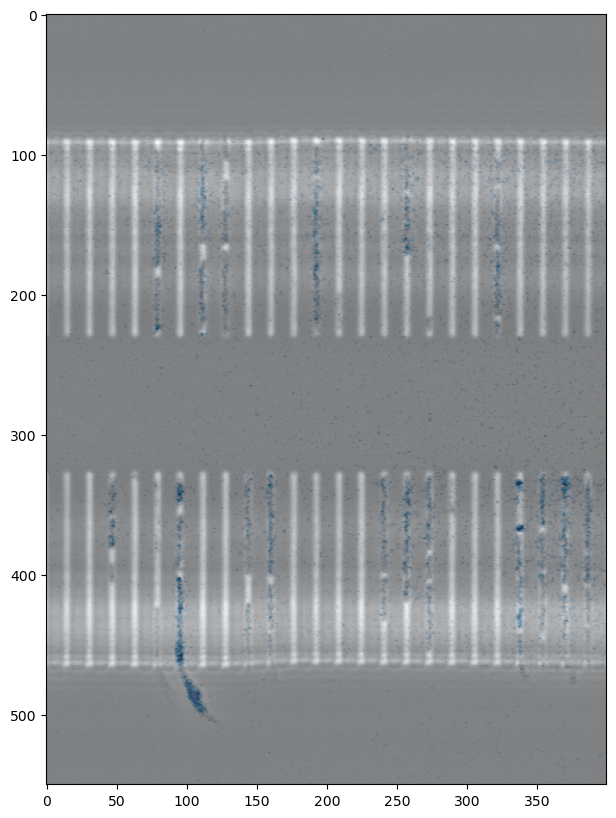

In [24]:
fov = 0
plt.imshow(barcodes[fov, :, :], cmap='gray')
plt.imshow(barcodes_Cy5[fov, :, :], cmap='Blues', alpha=0.5, vmin=2500, vmax=3000)
# plt.imshow(experiment[fov, :, :], cmap='Reds', alpha=0.5, vmin=500, vmax=3000)

In [15]:
def rename_and_delete_channels_from_hdf5_files(
    filepath,
    seg_channel_initial_name = 'seg_cleaned',
    seg_channel_final_name = 'BF',
    channels_to_delete = ['seg', 'seg_cleaned']
):
    """
    Rename the segmentation channel in an HDF5 file and delete specified channels.
    Args:
        headpath (str): Path to the directory containing the HDF5 files.
        filename (str): Name of the HDF5 file to process.
        seg_channel_initial_name (str): Name of the initial segmentation channel to rename.
        seg_channel_final_name (str): New name for the segmentation channel.
        channels_to_delete (list): List of channel names to delete from the HDF5 file.
    Returns:
        int: Returns 0 upon successful completion.
    """
    with h5py.File(filepath,"r+") as infile:
        if seg_channel_final_name in infile.keys():
            del infile[seg_channel_final_name]
        infile[seg_channel_final_name]  = infile[seg_channel_initial_name]

        for seg_channel in channels_to_delete:
            if seg_channel in infile.keys():
                del infile[seg_channel]
    return 0


def delete_channels_from_hdf5_files(
    filepath,
    channels_to_delete = ['seg', 'seg_cleaned']
):
    """
    Rename the segmentation channel in an HDF5 file and delete specified channels.
    Args:
        headpath (str): Path to the directory containing the HDF5 files.
        filename (str): Name of the HDF5 file to process.
        seg_channel_initial_name (str): Name of the initial segmentation channel to rename.
        seg_channel_final_name (str): New name for the segmentation channel.
        channels_to_delete (list): List of channel names to delete from the HDF5 file.
    Returns:
        int: Returns 0 upon successful completion.
    """
    with h5py.File(filepath,"r+") as infile:
        for seg_channel in channels_to_delete:
            if seg_channel in infile.keys():
                del infile[seg_channel]
    return 0

In [8]:
headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/'
headpath+'/run/'+'fov=100_config=BF_t=1.hdf5'

'/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01//run/fov=100_config=BF_t=1.hdf5'

In [9]:
# List all filenames
filename_pattern = f'fov=*_config=*_t=*.hdf5'
file_list = glob.glob(os.path.join(headpath+'/run/', filename_pattern))

In [11]:
# Deploy the function to rename and delete channels in all files
df_futures = deploy_function_in_dask(rename_and_delete_channels_from_hdf5_files,
                                     file_list,
                                     seg_channel_initial_name='corrected_positive_drift',
                                     seg_channel_final_name='data',
                                     channels_to_delete=['corrected'])

In [16]:
# Deploy the function to rename and delete channels in all files
df_futures = deploy_function_in_dask(delete_channels_from_hdf5_files,
                                     file_list,
                                     channels_to_delete=['corrected_positive_drift'])

In [17]:
with h5py.File(headpath+'/run/'+'fov=100_config=BF_t=1.hdf5', 'r') as f:
    print(f.keys())
    # print(f['BF'].shape)
    # print(f['BF'].dtype)

<KeysViewHDF5 ['data']>
